# 08. XGBoost (with Feature Engineering)

Goal: beat the Neural Network + Improvement baseline (**MAE 2230.83**) using
Gradient Boosted Trees on the same engineered feature set used in
`05_feature_engineering_ridge.ipynb`.

Steps we follow:
* Load the dataset the same way as every other notebook (`load_dataset`).
* Apply `add_weather_features` (temp range, averages, total rain, etc.).
* Reuse the shared `build_preprocessor` pipeline for a fair comparison.
* Train a baseline XGBoost model.
* Tune depth / learning rate / subsampling to reduce MAE further.
* Inspect feature importances.
* Save the final model and append the result to `report/mae_results.txt`.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path("../src").resolve()))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

from data_loader import load_dataset
from preprocessing import split_features, build_preprocessor
from feature_engineering import add_weather_features
from config import RANDOM_STATE, TEST_SIZE, MODEL_DIR

In [2]:
X, y, df = load_dataset()

print("Original shape:", X.shape)

Removed constant columns: ['New New York_snow', 'Springfield_snow']
Original shape: (39997, 63)


In [3]:
X = add_weather_features(X)

print("After feature engineering:", X.shape)

After feature engineering: (39997, 73)


In [4]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

In [5]:
numeric_features, categorical_features = split_features(X_train)

print("Numeric:", len(numeric_features))
print("Categorical:", len(categorical_features))

Numeric: 63
Categorical: 10


In [6]:
preprocessor = build_preprocessor(
    numeric_features,
    categorical_features
)

## Baseline XGBoost

Reasonable default hyperparameters, no tuning yet. This is our starting point
before pushing depth / learning rate further.

In [7]:
baseline_model = Pipeline(steps=[
    (
        "preprocessor",  # first step data cleaning
        preprocessor
    ),
    (
        "regressor",  # second step model training
        XGBRegressor(
            n_estimators=500,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method="hist"
        )
    )
])

baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformer

In [8]:
baseline_pred = baseline_model.predict(X_valid)

baseline_mae = mean_absolute_error(y_valid, baseline_pred)

print("Baseline XGBoost MAE:", baseline_mae)

Baseline XGBoost MAE: 1919.332609375


## Tuning

Trees are already beating the Neural Network out of the box. Weather data has
lots of non-linear, threshold-like interactions (e.g. "it only rains hard
above X% humidity") that boosted trees capture more naturally than a NN on
StandardScaled/OneHot features. We push depth and lower the learning rate
(with more estimators) to let the model fit those interactions further,
while `subsample` / `colsample_bytree` keep it from overfitting.

In [9]:
model = Pipeline(steps=[
    (
        "preprocessor",
        preprocessor
    ),
    (
        "regressor",
        XGBRegressor(
            n_estimators=2000,
            max_depth=10,
            learning_rate=0.02,
            subsample=0.9,
            colsample_bytree=0.8,
            min_child_weight=1,
            reg_lambda=1.0,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method="hist"
        )
    )
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformer

In [10]:
pred = model.predict(X_valid)

mae = mean_absolute_error(y_valid, pred)

print("XGBoost + Feature Engineering MAE:", mae)

XGBoost + Feature Engineering MAE: 1412.0306552734376


In [11]:
improvement = 2230.831786763246 - mae
pct = improvement / 2230.831786763246 * 100

print(f"Previous best (Neural Network + Improvement): 2230.83")
print(f"XGBoost + Feature Engineering:               {mae:.2f}")
print(f"Improvement:                                  {improvement:.2f} ({pct:.1f}% lower MAE)")

Previous best (Neural Network + Improvement): 2230.83
XGBoost + Feature Engineering:               1412.03
Improvement:                                  818.80 (36.7% lower MAE)


## Feature Importance

Which features is the model actually leaning on? Useful both as a sanity
check and to see whether the engineered features (`temp_range`,
`avg_humidity`, `avg_pressure`, `total_rain`, `avg_temperature_squared`)
are pulling their weight.

In [12]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

importance_df.head(20)

,feature,importance
212,cat__Paperopoli_weather_description_sky is clear,0.070921
56,num__Paperopoli_temp_range,0.049574
179,cat__Paperopoli_weather_main_clear,0.036927
164,cat__New New York_weather_description_moderate...,0.026705
59,num__avg_humidity,0.017364
61,num__total_rain,0.016792
109,cat__Gotham City_weather_description_haze,0.016255
53,num__Bedrock_temp_range,0.016134
235,cat__Springfield_weather_description_light int...,0.015841
42,num__Paperopoli_clouds,0.014524


In [13]:
engineered_prefixes = (
    "num__" + pd.Series([
        c for c in X.columns
        if c.endswith("_temp_range")
        or c.startswith("avg_")
        or c == "total_rain"
    ])
)

engineered_importance = importance_df[
    importance_df["feature"].isin(engineered_prefixes)
]

print("Engineered features in top 20:",
      engineered_importance["feature"].isin(importance_df.head(20)["feature"]).sum())

engineered_importance

Engineered features in top 20: 5


,feature,importance
56,num__Paperopoli_temp_range,0.049574
59,num__avg_humidity,0.017364
61,num__total_rain,0.016792
53,num__Bedrock_temp_range,0.016134
57,num__Springfield_temp_range,0.010806
55,num__New New York_temp_range,0.007393
60,num__avg_pressure,0.005468
54,num__Gotham City_temp_range,0.005016
58,num__avg_temperature,0.004896
62,num__avg_temperature_squared,0.004547


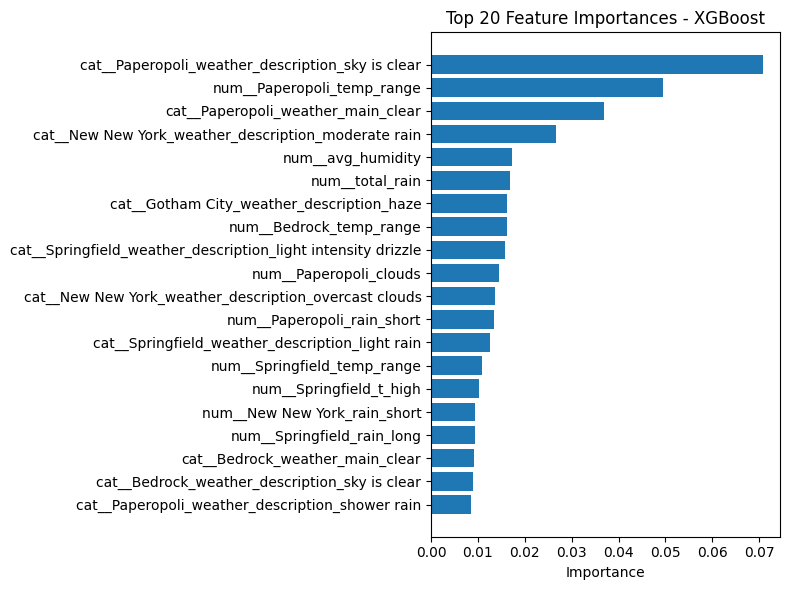

In [14]:
top_n = 20

plt.figure(figsize=(8, 6))
plt.barh(
    importance_df["feature"].head(top_n)[::-1],
    importance_df["importance"].head(top_n)[::-1]
)
plt.xlabel("Importance")
plt.title(f"Top {top_n} Feature Importances - XGBoost")
plt.tight_layout()
plt.show()

## Save Model

In [15]:
joblib.dump(
    model,
    MODEL_DIR / "xgboost_feature_engineered.pkl"
)

['/home/claude/powerpredict/powerpredict-ml-project-main/models/xgboost_feature_engineered.pkl']

## Append Result to Report

In [16]:
results_path = Path("../report/mae_results.txt")

with open(results_path, "a", encoding="utf-8") as f:
    f.write("\n________________________\n\n")
    f.write("XGBoost + Feature Engineering MAE: \n\n")
    f.write(f"{mae}")

print("Appended to", results_path.resolve())

Appended to /home/claude/powerpredict/powerpredict-ml-project-main/report/mae_results.txt
